# Advanced Chart Types

Some questions need more than bars, lines and scatter plots: change between two moments, distributions of many groups, matrices of values, or connections between entities. This lesson builds the most useful advanced chart types with matplotlib and seaborn.

**After this lesson you can:**

1. Show change with slope charts and dumbbell plots.
2. Compare many distributions with ridgeline plots.
3. Show matrices with annotated and clustered heatmaps.
4. Compare many series with small multiples.
5. Draw networks of flows with NetworkX.

**Data:** Gapminder, Seattle weather and NYC taxi trips (borough-to-borough flows).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

import networkx as nx
import seaborn as sns

gap = pd.read_json(datasets.fetch("gapminder.json"))
weather = pd.read_csv(datasets.fetch("seattle-weather.csv"), parse_dates=["date"])

## 1. Slope Chart and Dumbbell Plot

A **slope chart** connects two values per item (before → after); the slope shows the change. A **dumbbell plot** shows the same as two dots on one line per item, which scales to more items.

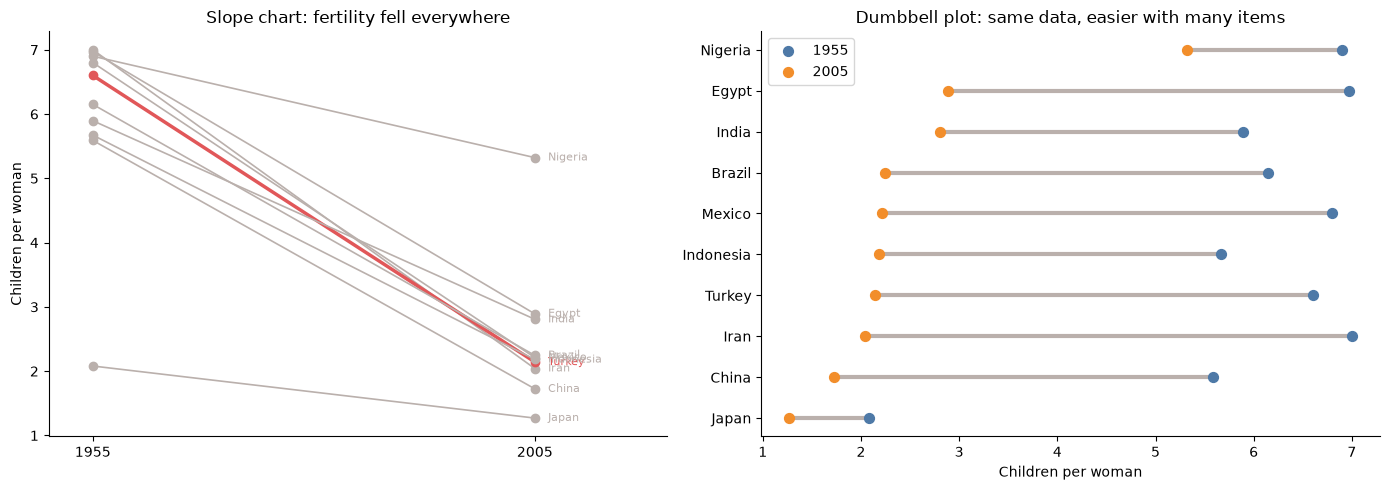

In [2]:
pick = [c for c in ["Turkey", "Brazil", "China", "India", "Nigeria", "Japan", "Egypt", "Mexico", "Iran", "Indonesia"] if c in set(gap["country"])]
fert = gap[gap["country"].isin(pick) & gap["year"].isin([1955, 2005])].pivot(index="country", columns="year", values="fertility")
fert = fert.sort_values(2005)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for c, row in fert.iterrows():
    color = "#E15759" if c == "Turkey" else "#BAB0AC"
    ax1.plot([0, 1], [row[1955], row[2005]], color=color, lw=2.5 if c == "Turkey" else 1.2, marker="o")
    ax1.text(1.03, row[2005], c, va="center", fontsize=8, color=color)
ax1.set(xticks=[0, 1], xticklabels=["1955", "2005"], xlim=(-0.1, 1.3), ylabel="Children per woman",
        title="Slope chart: fertility fell everywhere")
ax2.hlines(fert.index, fert[2005], fert[1955], color="#BAB0AC", lw=3)
ax2.scatter(fert[1955], fert.index, color="#4E79A7", s=50, label="1955", zorder=3)
ax2.scatter(fert[2005], fert.index, color="#F28E2B", s=50, label="2005", zorder=3)
ax2.set(title="Dumbbell plot: same data, easier with many items", xlabel="Children per woman")
ax2.legend()
plt.tight_layout()
plt.show()

## 2. Ridgeline Plot

A **ridgeline plot** stacks density curves of many groups with a small overlap. It shows how a distribution shifts across groups, for example the daily maximum temperature per month.

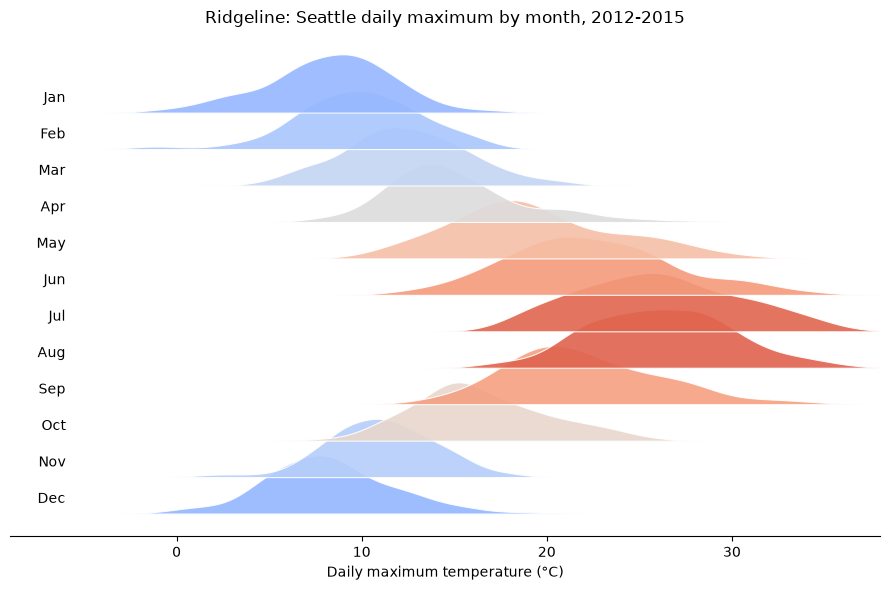

In [3]:
from scipy.stats import gaussian_kde

weather["month"] = weather["date"].dt.month
xs = np.linspace(-5, 38, 300)
fig, ax = plt.subplots(figsize=(9, 6))
cmap = plt.cm.coolwarm
for i, m in enumerate(range(12, 0, -1)):
    vals = weather.loc[weather["month"] == m, "temp_max"]
    dens = gaussian_kde(vals)(xs)
    dens = dens / dens.max() * 1.6
    ax.fill_between(xs, i, i + dens, color=cmap(vals.mean() / 30), alpha=0.9, lw=0.8, edgecolor="white")
    ax.text(-6, i + 0.2, pd.Timestamp(2000, m, 1).strftime("%b"), ha="right", va="bottom")
ax.set(yticks=[], xlabel="Daily maximum temperature (°C)", title="Ridgeline: Seattle daily maximum by month, 2012-2015", xlim=(-9, 38))
ax.spines["left"].set_visible(False)
plt.tight_layout()
plt.show()

## 3. Heatmaps: Annotated and Clustered

A **heatmap** encodes a matrix with colour. Annotate the cells when exact values matter. A **clustered heatmap** reorders rows and columns so that similar ones sit next to each other (hierarchical clustering), which reveals groups.

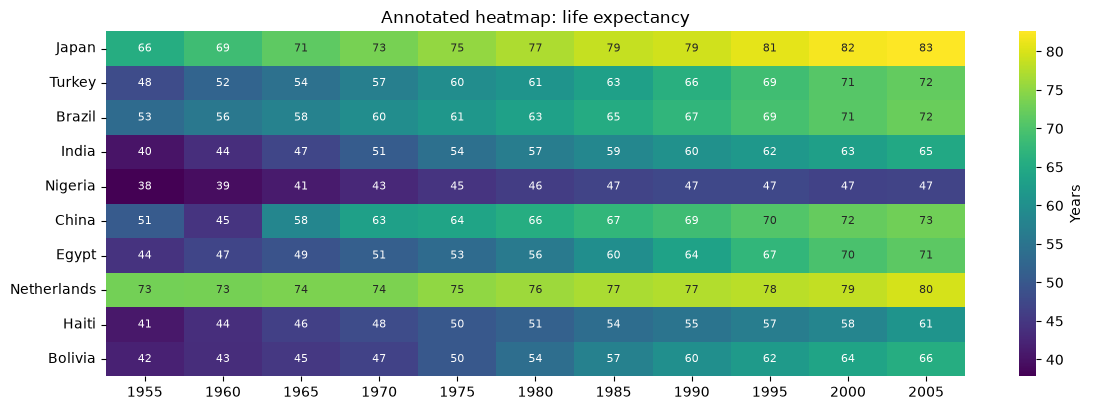

In [4]:
wide = gap.pivot(index="country", columns="year", values="life_expect")
sample = wide.loc[[c for c in ["Japan", "Turkey", "Brazil", "India", "Nigeria", "China", "Egypt", "Netherlands", "Haiti", "Bolivia"]
                    if c in wide.index]]
fig, ax = plt.subplots(figsize=(12, 4.2))
sns.heatmap(sample, annot=True, fmt=".0f", cmap="viridis", cbar_kws={"label": "Years"}, ax=ax, annot_kws={"fontsize": 8})
ax.set(title="Annotated heatmap: life expectancy", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

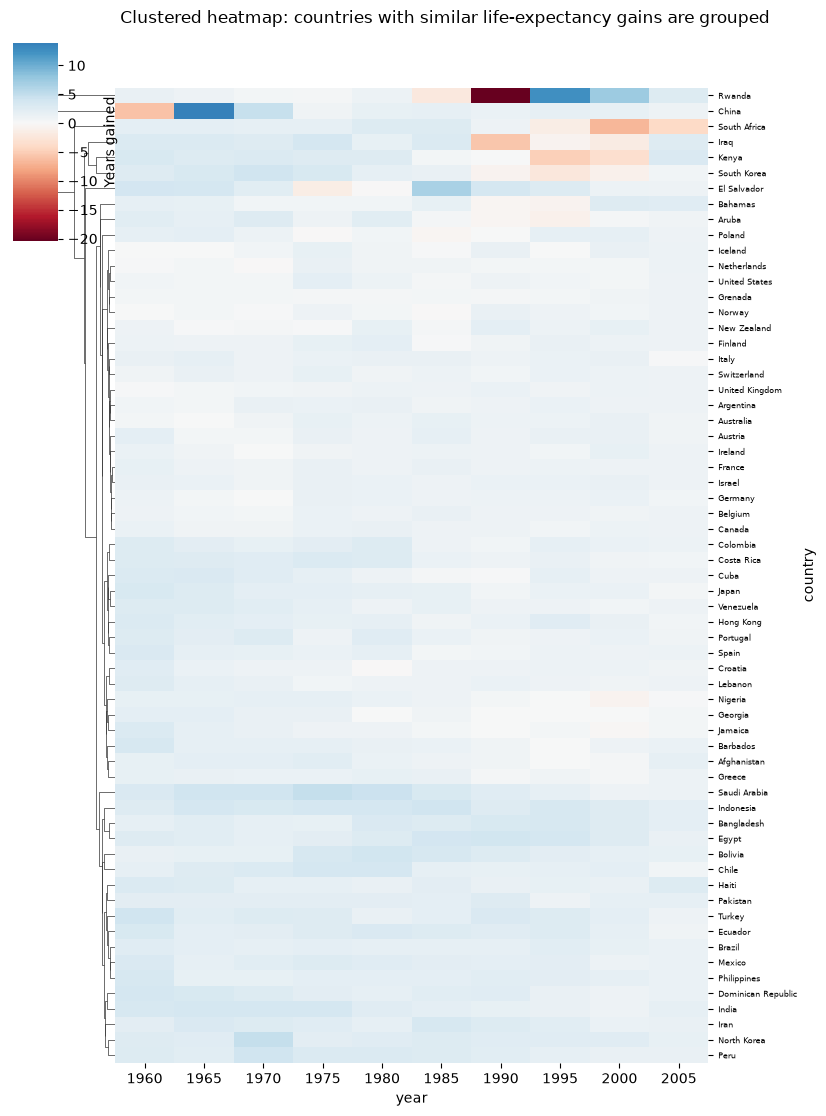

In [5]:
change = wide.diff(axis=1).iloc[:, 1:]                     # gain per 5-year step
g = sns.clustermap(change, cmap="RdBu", center=0, col_cluster=False, figsize=(9, 11), cbar_kws={"label": "Years gained"},
                   yticklabels=True, dendrogram_ratio=(0.15, 0.05))
g.ax_heatmap.tick_params(axis="y", labelsize=6)
g.figure.suptitle("Clustered heatmap: countries with similar life-expectancy gains are grouped", y=1.01)
plt.show()

The clustered rows group countries with similar histories. The red cells late in the series mark falls in life expectancy in the 1990s: Rwanda (the 1994 genocide, about −20 years in one step), South Africa and Kenya (the HIV/AIDS epidemic) and Iraq (wars and sanctions).

## 4. Small Multiples

Instead of 12 overlapping lines, draw 12 small charts with the same axes. Add the other series in light grey as context in every panel.

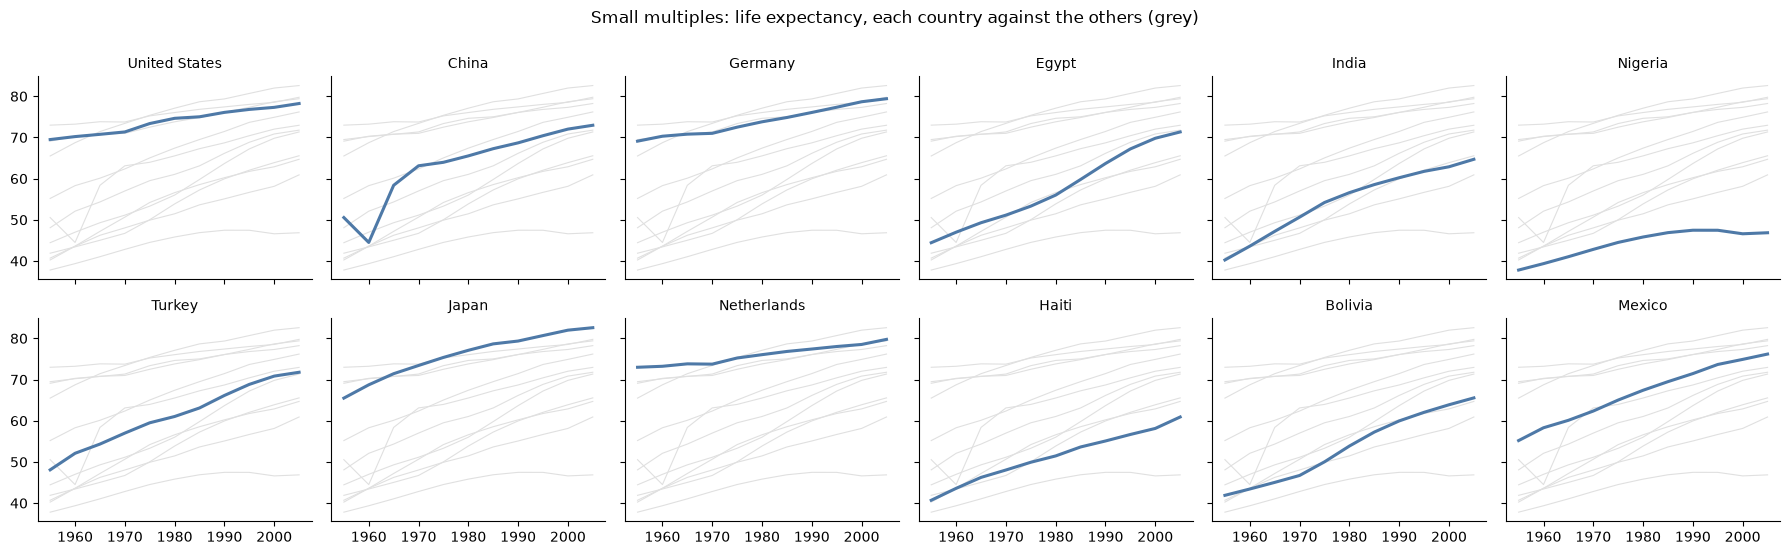

In [6]:
regions = {0: "South Asia", 1: "Europe & Central Asia", 2: "Sub-Saharan Africa", 3: "Americas", 4: "East Asia & Pacific",
           5: "Middle East & North Africa"}
gap["region"] = gap["cluster"].map(regions)
countries = gap.groupby("region")["pop"].idxmax()
extra = [c for c in ["Turkey", "Japan", "Nigeria", "Netherlands", "Haiti", "Bolivia", "Egypt", "Germany", "Mexico"] if c in set(gap["country"])]
focus = list(dict.fromkeys(gap.loc[countries, "country"].tolist() + extra))[:12]
fig, axes = plt.subplots(2, 6, figsize=(18, 5.5), sharex=True, sharey=True)
for ax, c in zip(axes.flat, focus):
    for other in focus:
        part = gap[gap["country"] == other]
        ax.plot(part["year"], part["life_expect"], color="#E0E0E0", lw=0.8)
    part = gap[gap["country"] == c]
    ax.plot(part["year"], part["life_expect"], color="#4E79A7", lw=2.2)
    ax.set_title(c, fontsize=10)
fig.suptitle("Small multiples: life expectancy, each country against the others (grey)", y=1.0)
plt.tight_layout()
plt.show()

## 5. Network of Flows

A **network graph** shows entities (nodes) and connections (edges). Here: taxi trips between the five boroughs of New York in January 2024. Node size = trips starting there; edge width = trips between two boroughs.

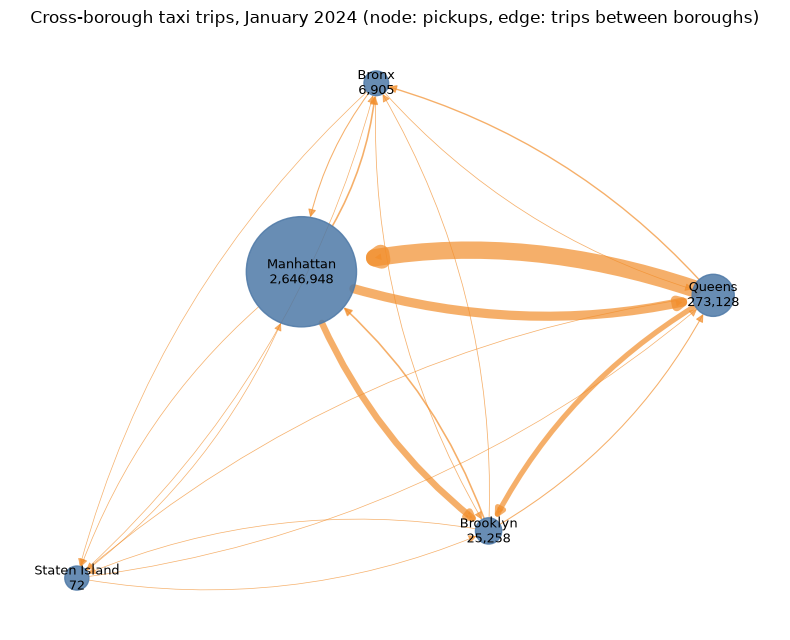

      src       dst  trips
   Queens Manhattan 150203
Manhattan    Queens  76535
Manhattan  Brooklyn  52145
   Queens  Brooklyn  41086


In [7]:
taxi = pd.read_parquet(datasets.taxi("2024-01"), columns=["PULocationID", "DOLocationID"])
zones = pd.read_csv(datasets.fetch("taxi_zone_lookup.csv")).set_index("LocationID")["Borough"]
flows = (taxi.assign(src=taxi["PULocationID"].map(zones), dst=taxi["DOLocationID"].map(zones))
         .query("src != dst and src not in ['Unknown', 'N/A', 'EWR'] and dst not in ['Unknown', 'N/A', 'EWR']")
         .groupby(["src", "dst"]).size().reset_index(name="trips"))
starts = taxi["PULocationID"].map(zones).value_counts()

G = nx.DiGraph()
for r in flows.itertuples():
    G.add_edge(r.src, r.dst, weight=r.trips)
pos = {"Manhattan": (0, 0.3), "Bronx": (0.2, 1.1), "Queens": (1.1, 0.2), "Brooklyn": (0.5, -0.8), "Staten Island": (-0.6, -1.0)}
widths = [0.5 + 12 * G[u][v]["weight"] / flows["trips"].max() for u, v in G.edges()]
sizes = [300 + 6000 * starts.get(n, 0) / starts.max() for n in G.nodes()]

fig, ax = plt.subplots(figsize=(8, 6.5))
nx.draw_networkx_nodes(G, pos, node_size=sizes, node_color="#4E79A7", alpha=0.85, ax=ax)
nx.draw_networkx_edges(G, pos, width=widths, edge_color="#F28E2B", alpha=0.7, arrows=True, arrowsize=12,
                       connectionstyle="arc3,rad=0.15", node_size=sizes, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=9, font_color="black", ax=ax,
                        labels={n: f"{n}\n{starts.get(n, 0):,}" for n in G.nodes()})
ax.set(title="Cross-borough taxi trips, January 2024 (node: pickups, edge: trips between boroughs)")
ax.axis("off")
plt.tight_layout()
plt.show()
print(flows.sort_values("trips", ascending=False).head(4).to_string(index=False))

| Chart | Use when | Avoid when |
| :--- | :--- | :--- |
| slope / dumbbell | two moments per item | more than two moments (use lines) |
| ridgeline | distributions of 5–20 ordered groups | exact comparison of values |
| heatmap | matrices, calendars, correlations | precise values without annotations |
| small multiples | many series with the same scale | series with very different scales |
| network | connections are the question | more than ~50 nodes without filtering |

*Insight: Advanced charts are tools for specific questions. Choose a slope chart for change, small multiples for many series, a ridgeline for many distributions, a heatmap for matrices, and a network when connections are the point, and keep the principles of Lesson 01.*

## Real-World Use Case or Analogy

Advanced chart types are like **specialised kitchen knives**: a bread knife, a filleting knife and a paring knife each do one job much better than a general knife, but nobody uses a filleting knife to spread butter.

Newsrooms use small multiples and slope charts for elections and economic data; genomics uses clustered heatmaps; transport planners use flow networks and maps (Lesson 05) to plan routes.